In [13]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)


#ZAD1

In [14]:
#ZAD1
def get_neighbors(state):
    r, c = state

    #zamiana ruchow
    moves = [
        (0, -1),  # lewo
        (0, 1),   # prawo
        (-1, 0),  # góra
        (1, 0),   # dół
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(0, 1)]


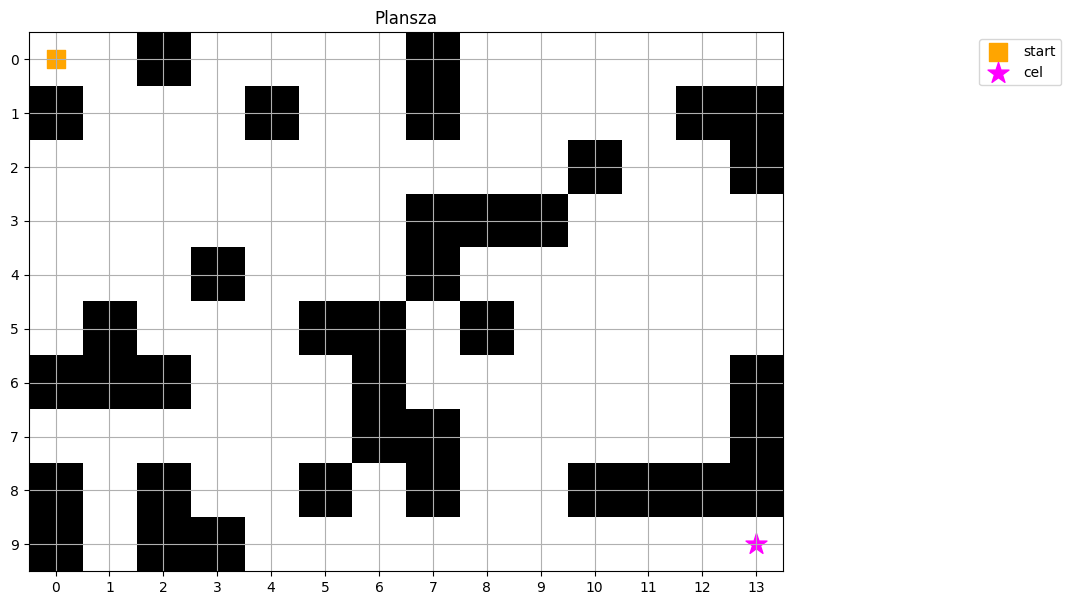

In [15]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()

BFS - długość ścieżki: 22
BFS - odwiedzone stany: 102
BFS - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


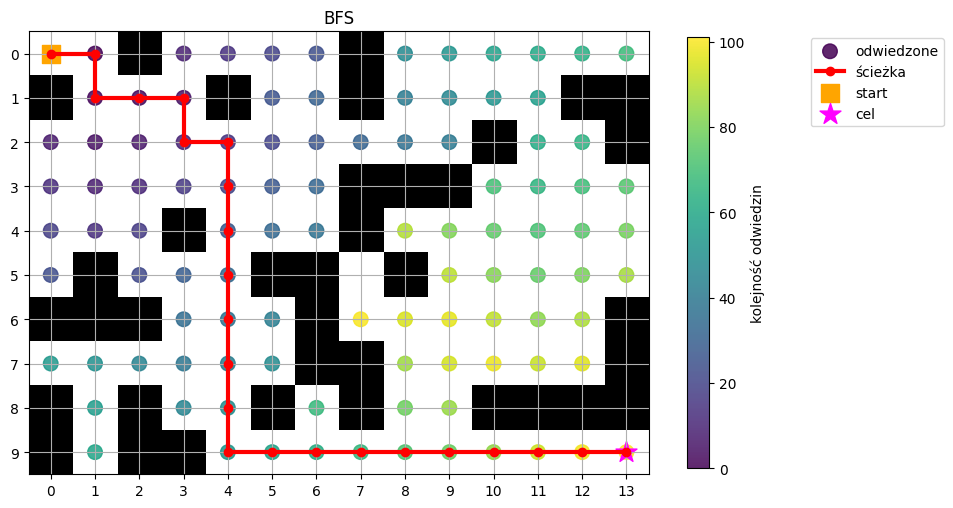

In [16]:
def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")


DFS - długość ścieżki: 28
DFS - odwiedzone stany: 30
DFS - ścieżka: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (5, 2), (5, 3), (6, 3), (7, 3), (8, 3), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (8, 8), (7, 8), (6, 8), (6, 9), (7, 9), (8, 9), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


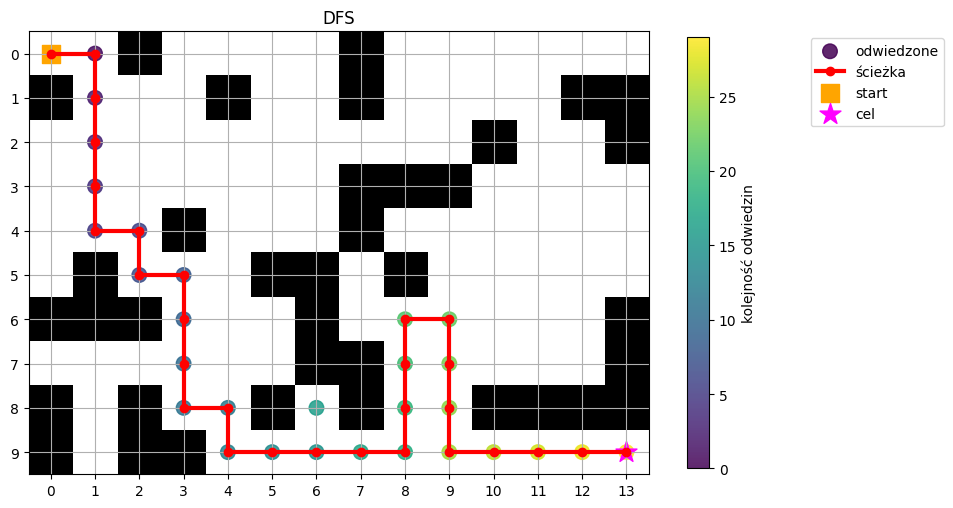

In [17]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

# ZAD1
Po zmianie ruchów w get_neighbors() algorytm DFS znalazł inną ścieżkę i zmieniła się lista odwiedzonych stanów. Dzieje się tak ponieważ algorytm szuka w głąb i zmiana kolejności ruchów powoduje zmianę gałęzi w którą algorytm skręci jako pierwszą, algorytm w każdym rozwidleniu wybierze zupełnie inny kierunkek, co całkowicie zmieni jego trasę.

In [18]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81
(4, 6) Manhattan = 12 Euclidean = 8.6
(7, 10) Manhattan = 5 Euclidean = 3.61
(9, 12) Manhattan = 1 Euclidean = 1.0


A* - koszt: 22
A* - odwiedzone stany: 46
A* - ścieżka: [(0, 0), (0, 1), (1, 1), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


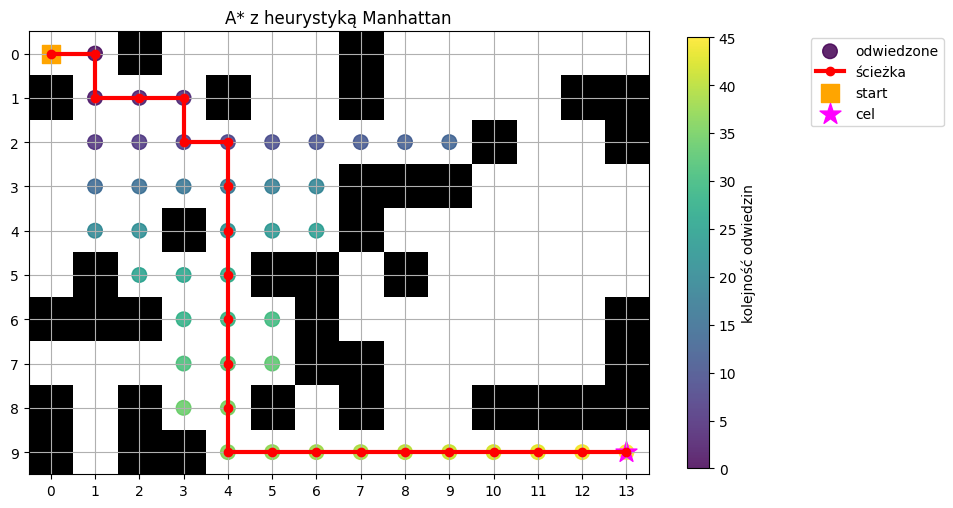

In [19]:
def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")

# ZAD2

BFS - długość ścieżki: 24
BFS - odwiedzone stany: 91
BFS - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


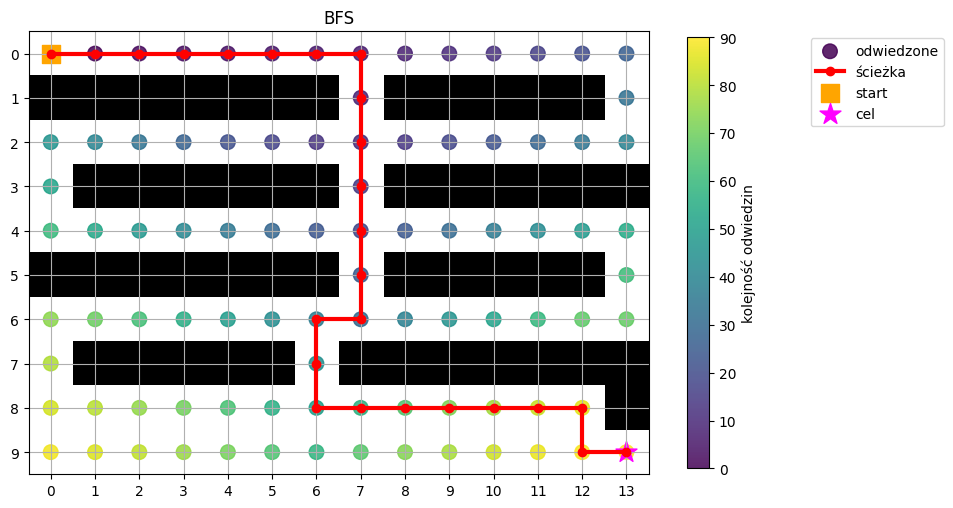

A* - koszt: 24
A* - odwiedzone stany: 59
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


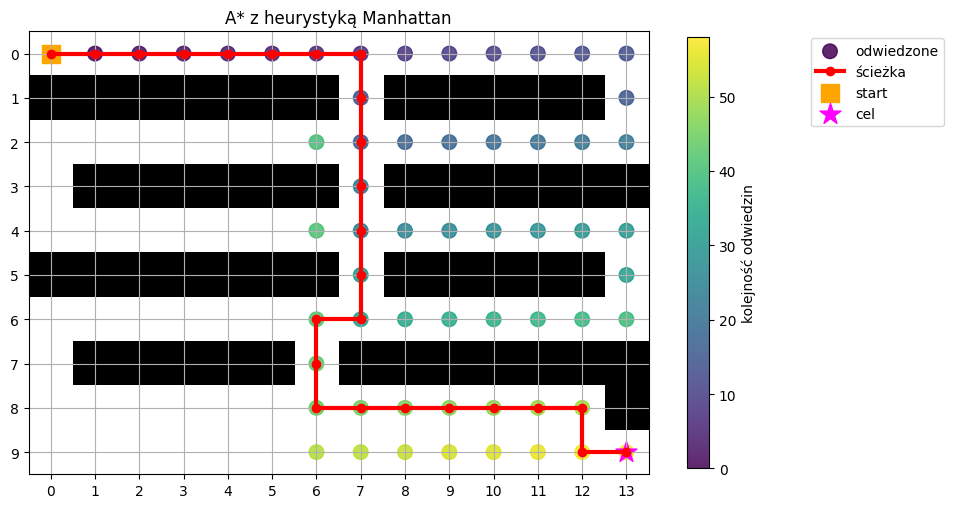

In [51]:
MAPA2 = [
    "..............",
    "#######.#####.",
    "..............",
    ".######.######",
    "..............",
    "#######.#####.",
    "..............",
    ".#####.#######",
    ".............#",
    "..............",
]

grid2 = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA2]

def get_neighbors2(state):
    r, c = state

    #zamiana ruchow
    moves = [
        (0, -1),  # lewo
        (0, 1),   # prawo
        (-1, 0),  # góra
        (1, 0),   # dół
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid2[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors

def draw_grid2(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid2]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()

def bfs2(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors2(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path2, bfs_visited2 = bfs2(start, goal)

print("BFS - długość ścieżki:", len(bfs_path2) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited2))
print("BFS - ścieżka:", bfs_path2)

draw_grid2(bfs_path2, bfs_visited2, "BFS")



def astar2(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors2(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path2, astar_visited2, astar_cost2 = astar2(start, goal)

print("A* - koszt:", astar_cost2)
print("A* - odwiedzone stany:", len(astar_visited2))
print("A* - ścieżka:", astar_path2)

draw_grid2(astar_path2, astar_visited2, "A* z heurystyką Manhattan")


# ZAD3

A* - koszt: 24
A* - odwiedzone stany: 59
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


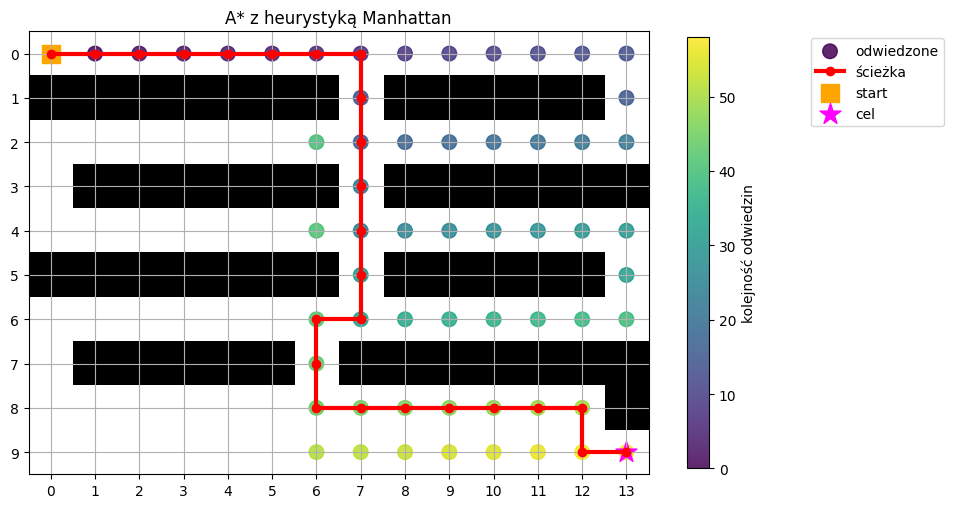

A* - koszt: 24
A* - odwiedzone stany: 63
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


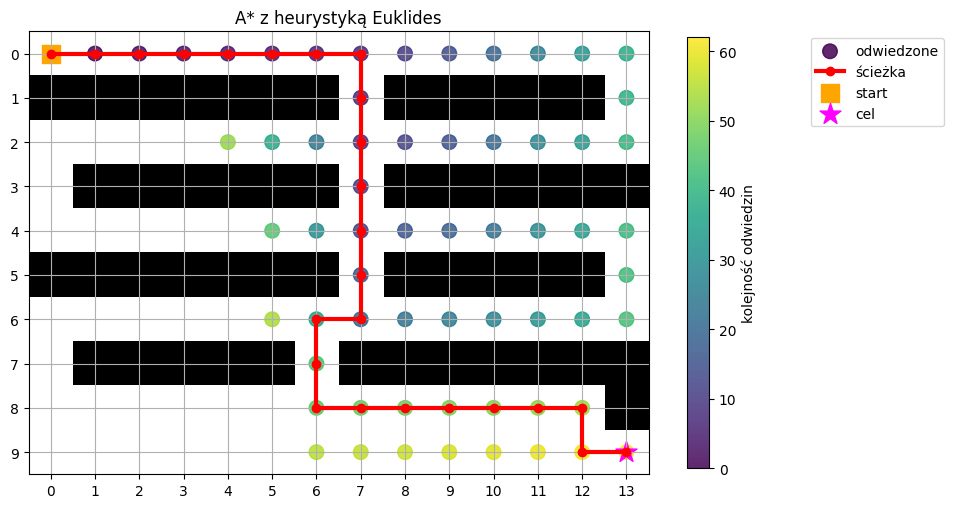

A* - koszt: 24
A* - odwiedzone stany: 91
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


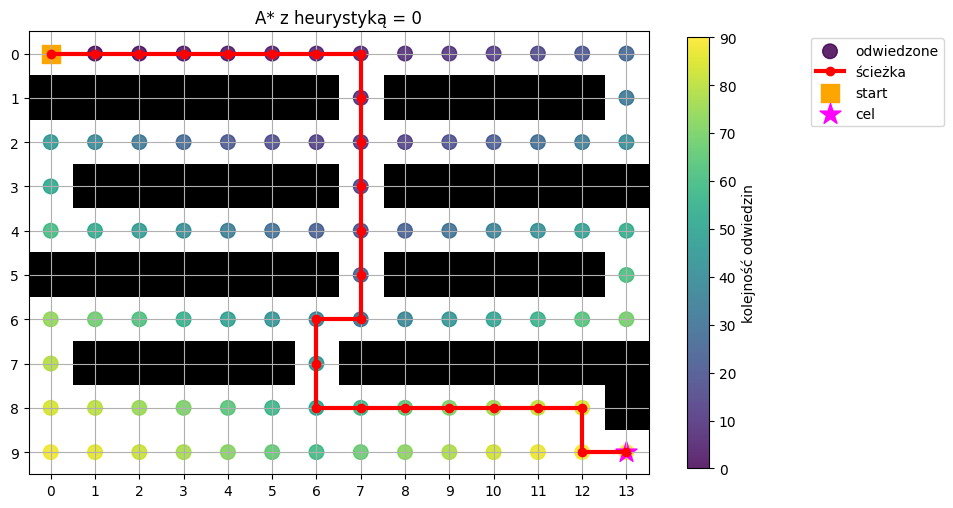

A* - koszt: 24
A* - odwiedzone stany: 65
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 12), (9, 13)]


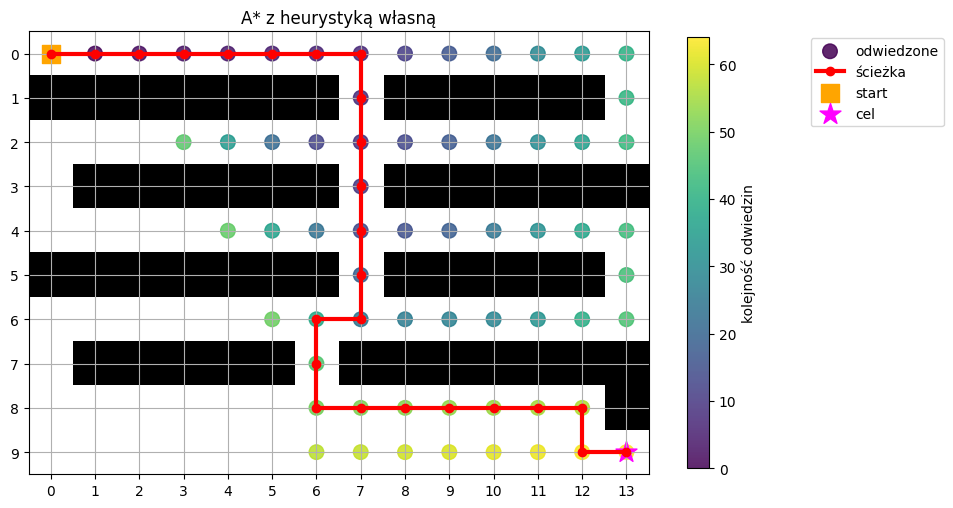

In [73]:
#odleglosc Czebyszewa
def my_heuristic(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))

#M
print("A* - koszt:", astar_cost2)
print("A* - odwiedzone stany:", len(astar_visited2))
print("A* - ścieżka:", astar_path2)
draw_grid2(astar_path2, astar_visited2, "A* z heurystyką Manhattan")

#E
astar_path_e, astar_visited_e, astar_cost_e = astar2(start, goal, euclidean)
print("A* - koszt:", astar_cost_e)
print("A* - odwiedzone stany:", len(astar_visited_e))
print("A* - ścieżka:", astar_path_e)
draw_grid2(astar_path_e, astar_visited_e, "A* z heurystyką Euklides")

#h(n)=0
def zero_heuristic(a, b):
    return 0
astar_path_0, astar_visited_0, astar_cost_0 = astar2(start, goal, zero_heuristic)
print("A* - koszt:", astar_cost_0)
print("A* - odwiedzone stany:", len(astar_visited_0))
print("A* - ścieżka:", astar_path_0)
draw_grid2(astar_path_0, astar_visited_0, "A* z heurystyką = 0")

#Wlasna
astar_path3, astar_visited3, astar_cost3 = astar2(start, goal, my_heuristic)
print("A* - koszt:", astar_cost3)
print("A* - odwiedzone stany:", len(astar_visited3))
print("A* - ścieżka:", astar_path3)
draw_grid2(astar_path3, astar_visited3, "A* z heurystyką własną")



# ZAD4

A* - koszt: 21.656854249492383
A* - odwiedzone stany: 51
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 6), (8, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


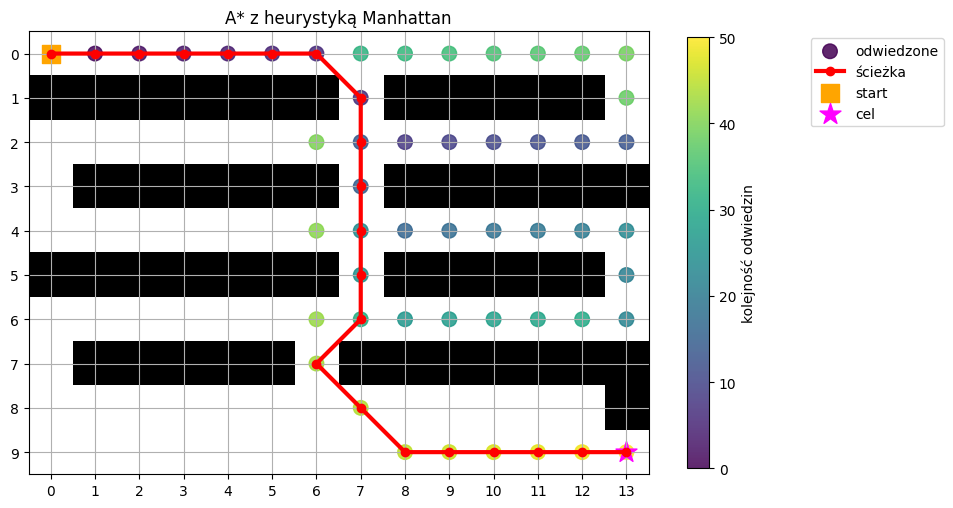

A* - koszt: 21.656854249492383
A* - odwiedzone stany: 57
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 13)]


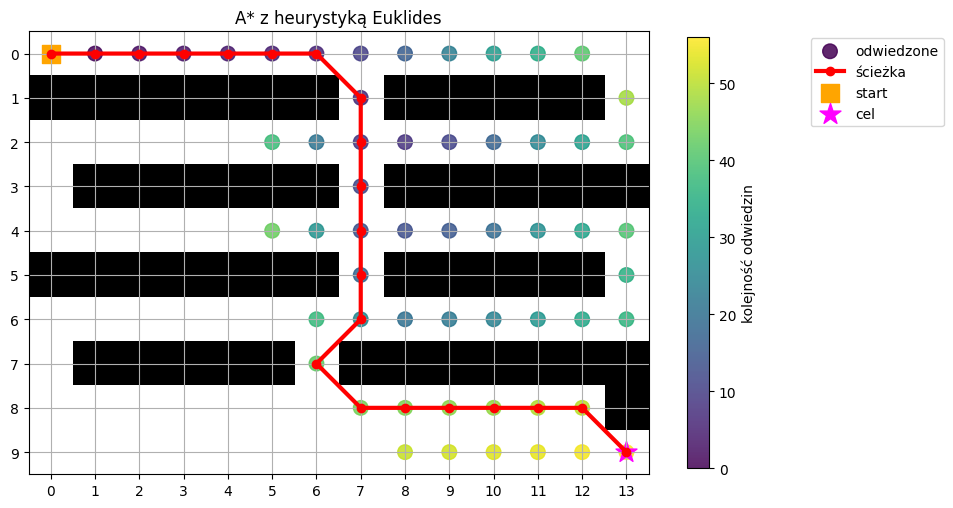

A* - koszt: 21.656854249492383
A* - odwiedzone stany: 91
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 13)]


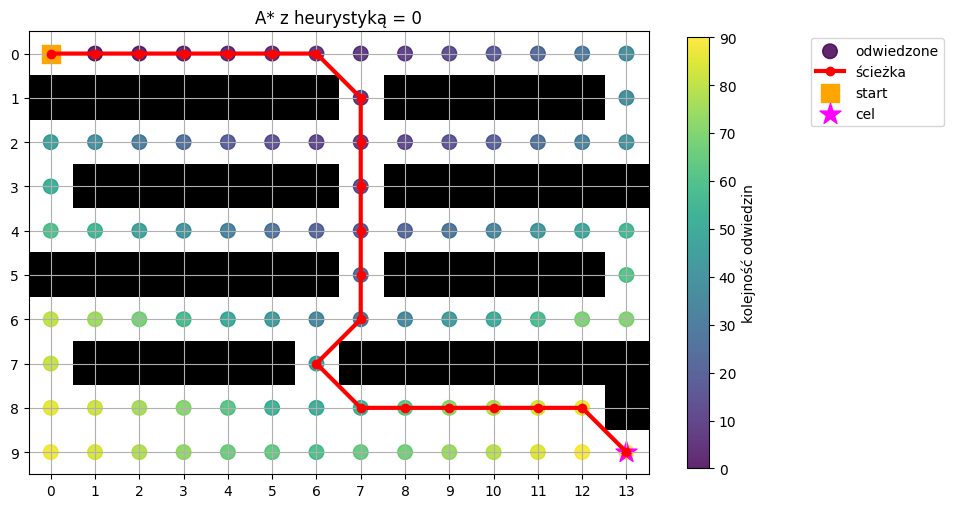

A* - koszt: 21.656854249492383
A* - odwiedzone stany: 58
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 6), (8, 7), (8, 8), (8, 9), (8, 10), (8, 11), (8, 12), (9, 13)]


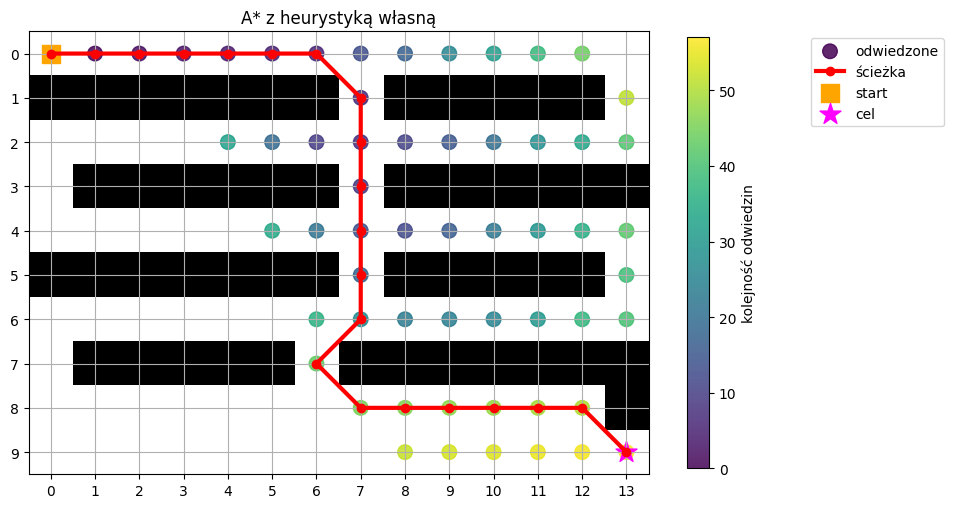

In [77]:
def get_neighbors4(state):
    r, c = state

    #zamiana ruchow i dodanie kosztu ruchu
    moves = [
        (0, -1, 1),  # lewo
        (0, 1, 1),   # prawo
        (-1, 0, 1),  # góra
        (1, 0, 1),   # dół
        (1, 1, math.sqrt(2)),   # prawo-dol
        (1, -1, math.sqrt(2)),  # lewo-dol
        (-1, 1, math.sqrt(2)),  # prawo-gora
        (-1, -1, math.sqrt(2)), # lewo-gora
    ]

    neighbors = []

    for dr, dc, cost in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid2[nr][nc] == 0:
                neighbors.append(((nr, nc), cost))

    return neighbors


def astar4(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor, cost in get_neighbors4(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")

#M
astar_path4, astar_visited4, astar_cost4 = astar4(start, goal)
print("A* - koszt:", astar_cost4)
print("A* - odwiedzone stany:", len(astar_visited4))
print("A* - ścieżka:", astar_path4)
draw_grid2(astar_path4, astar_visited4, "A* z heurystyką Manhattan")

#E
astar_path_e, astar_visited_e, astar_cost_e = astar4(start, goal, euclidean)
print("A* - koszt:", astar_cost_e)
print("A* - odwiedzone stany:", len(astar_visited_e))
print("A* - ścieżka:", astar_path_e)
draw_grid2(astar_path_e, astar_visited_e, "A* z heurystyką Euklides")

#h(n)=0
def zero_heuristic(a, b):
    return 0
astar_path_0, astar_visited_0, astar_cost_0 = astar4(start, goal, zero_heuristic)
print("A* - koszt:", astar_cost_0)
print("A* - odwiedzone stany:", len(astar_visited_0))
print("A* - ścieżka:", astar_path_0)
draw_grid2(astar_path_0, astar_visited_0, "A* z heurystyką = 0")

#Wlasna
astar_path3, astar_visited3, astar_cost3 = astar4(start, goal, my_heuristic)
print("A* - koszt:", astar_cost3)
print("A* - odwiedzone stany:", len(astar_visited3))
print("A* - ścieżka:", astar_path3)
draw_grid2(astar_path3, astar_visited3, "A* z heurystyką własną")

1. Manhattan nie jest najlepszym wyborem ponieważ matematycznie w obliczaniu drogi nie uwzględnia ruchów po przekątnej tylko poziomo i pionowo (Chociaż na moim przypadku odwiedził mniej stanów, bo dając większe wartości wpływa na wzór f(n) = g(n) + h(n) i staje się bardziej agresywny).
2. Teoretycznie najlepszą heurystyką powinien być Euklides, bo opierając się na twierdzeniu Pitagorasa ruch po przekątnej kwadratu o bokach 1x1 to sqrt(2), czyli równy jest nadanemu kosztowi

# ZAD5

A* - koszt: 20.242640687119287
A* - odwiedzone stany: 21
A* - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (1, 6), (2, 6), (3, 6), (4, 6), (5, 6), (6, 6), (7, 6), (8, 7), (9, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


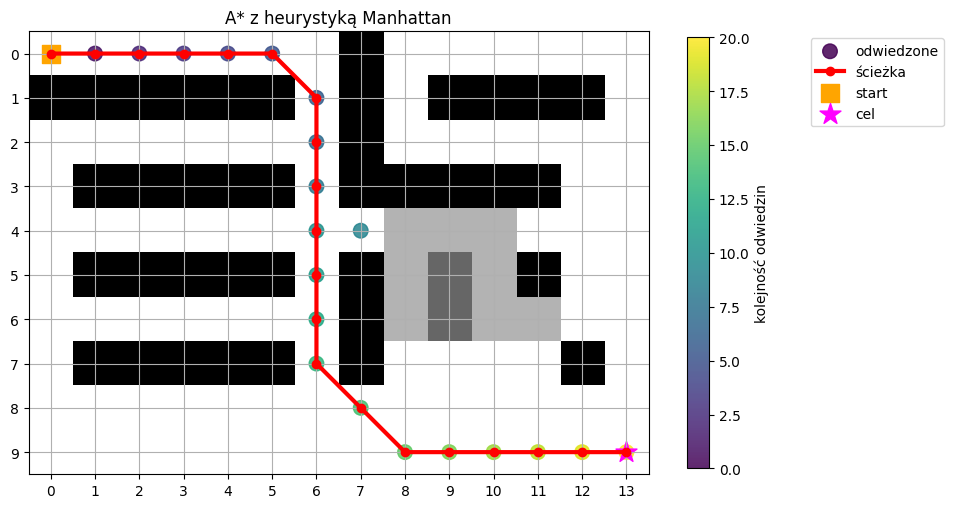

BFS - długość ścieżki: 15
BFS - odwiedzone stany: 83
BFS - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (1, 6), (2, 6), (3, 6), (4, 7), (4, 8), (5, 9), (6, 10), (7, 11), (8, 12), (9, 13)]


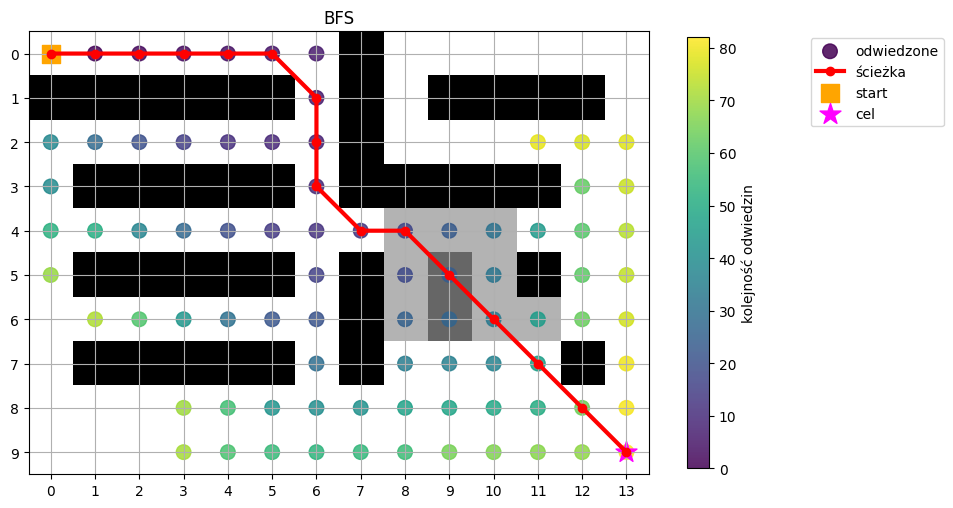

In [93]:
grid5 = [
    [1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1],
    [1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 1, 1, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 3, 5, 3, 0, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 0, 3, 5, 3, 3, 1, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
]

start = (0, 0)
goal = (9, 13)
rows = len(grid5)
cols = len(grid5[0])

def get_neighbors5(state):
    r, c = state

    #zamiana ruchow i dodanie kosztu ruchu
    moves = [
        (0, -1, 1),  # lewo
        (0, 1, 1),   # prawo
        (-1, 0, 1),  # góra
        (1, 0, 1),   # dół
        (1, 1, math.sqrt(2)),   # prawo-dol
        (1, -1, math.sqrt(2)),  # lewo-dol
        (-1, 1, math.sqrt(2)),  # prawo-gora
        (-1, -1, math.sqrt(2)), # lewo-gora
    ]

    neighbors = []
    for dr, dc, cost in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            cell_value = grid5[nr][nc]

            # Jesli pole to nie sciana (czyli cell_value > 0)
            if cell_value > 0:
                total_cost = cell_value * cost
                neighbors.append(((nr, nc), total_cost))

    return neighbors


def draw_grid5(path=None, visited=None, title="Plansza"):
    img = [[1.0 if cell == 1 else (0.7 if cell == 3 else (0.4 if cell == 5 else 0.0)) for cell in row] for row in grid5]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


def astar5(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor, cost in get_neighbors5(current):
            if neighbor in closed:
                continue

            tentative_g = g_score[current] + cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g
                f_score = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_heap, (f_score, neighbor))

    return None, visit_order, float("inf")
#M
astar_path5, astar_visited5, astar_cost5 = astar5(start, goal)
print("A* - koszt:", astar_cost5)
print("A* - odwiedzone stany:", len(astar_visited5))
print("A* - ścieżka:", astar_path5)
draw_grid5(astar_path5, astar_visited5, "A* z heurystyką Manhattan")



def bfs5(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor, _ in get_neighbors5(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path5, bfs_visited5 = bfs5(start, goal)

print("BFS - długość ścieżki:", len(bfs_path5) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited5))
print("BFS - ścieżka:", bfs_path5)

draw_grid5(bfs_path5, bfs_visited5, "BFS")


BFS nie gwarantuje już znalezienia najtańszej ścieżki, ponieważ nie uwzględnia różnych kosztów danej opcji ścieżki, znajduje po prostu najkrótszą

# ZAD6
- g(n) to koszt kroków które już wykonaliśmy
- h(n) to koszt szacunkowy kroków do
wykonania